# Thực thi Pohlig–Hellman trên smooth curve & so sánh chi phí

> **Topic 14 – ECC Cryptanalysis · Track A (generic ECDLP search)** <br>
> **Task:** *Thực thi PH trên smooth curve, so sánh chi phí (PH vs BSGS vs Pollard's rho)* <br>

### Quá trình
| Bước | Nội dung | Hàm chính |
|---|---|---|
| 0 | Môi trường, nạp lõi từ `gen_smooth_curves` / `toy_curve_gen` (import / fallback), công cụ đo | `measure`, `track_ecc_ops`, `get_cpu_freq_ghz` |
| 1 | Baby-step giant-step tổng quát (subroutine) + Pollard's rho (baseline generic thứ hai) | `bsgs_dlp`, `pollard_rho_dlp` |
| 2 | Định lý số dư Trung Hoa + thuật toán Pohlig–Hellman đầy đủ, kiểm tra trên ví dụ nhỏ (F_97) | `crt_combine`, `pohlig_hellman` |
| 3 | Đo chi phí PH vs BSGS vs Pollard's rho trên nhiều curve smooth (16–32 bit) và PH-only ở 40/48 bit | `benchmark_curve` |
| 4 | Ghi kết quả vào D2 (file theo curve + gộp vào `D2_ecdlp_benchmarks.csv`), vẽ biểu đồ đo thực tế vs ước lượng lý thuyết | `write_benchmark_csv`, `write_d2_csv`, `plot_benchmarks` |
| 5 | Selftest & CLI | `selftest`, `main` |

## Bước 0 – Môi trường và kế thừa lõi 

**0a.** Tự dò thư mục gốc dự án (chứa `curves/`) bất kể mở notebook từ đâu, để các đường dẫn `data/` và `docs/charts/`
luôn đúng.

In [5]:
import os, sys, platform, subprocess
from pathlib import Path

cwd = Path.cwd().resolve()
ROOT_DIR = next((p for p in [cwd, *cwd.parents] if (p / "curves").is_dir()), cwd)
for _p in (ROOT_DIR, ROOT_DIR / "curves", ROOT_DIR / "scripts"):
    if _p.is_dir() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

DATA_DIR = ROOT_DIR / "data"
CHARTS_DIR = ROOT_DIR / "docs" / "charts"
print("ROOT_DIR =", ROOT_DIR)

ROOT_DIR = /home/han-sui/ECC-Cryptanalysis


**0b.** Nạp lõi số học

In [7]:
from __future__ import annotations

import csv
import json
import random
import sys
import time
from math import isqrt, prod, sqrt
from pathlib import Path
from typing import Dict, List, Optional, Tuple

# 1. Import nền tảng toán học & các thuật toán ECDLP từ curves/ và scripts/
from curves.ecc import (
    ECC,
    Point,
    FindOrder,
    is_prime,
    random_prime,
    sqrt_mod,
    factorint as factorize,
)
from curves.pohlig_hellman import pohlig_hellman_ecc
from curves.bsgs import BSGS_ECC
from curves.pollard_rho import Pollard_Rho_ECC
from scripts.measure_harness import measure

# 2. Import bộ sinh & kiểm chứng đường cong chuẩn D1 từ curves/toy_curve_gen.py
from curves.toy_curve_gen import (
    D1_COLUMNS,
    GENERATION_METHOD,
    curve_from_row,
    base_point_from_row,
    count_points,
    count_points_naive,
    count_points_bsgs,
    classify,
    make_row,
    verify_row,
    write_csv,
    load_csv,
    parse_csv_row,
    generate_curve,
)


# 3. Các hàm phân tích độ phức tạp lý thuyết & sinh hàng loạt đường cong B-smooth
def estimate_bsgs_cost(n: int) -> float:
    """Chi phí lý thuyết O(sqrt(n)) của BSGS / Pollard's Rho."""
    return sqrt(n)


def estimate_ph_cost(fn: Dict[int, int]) -> float:
    """Chi phí lý thuyết sum(e_i * sqrt(q_i)) của Pohlig-Hellman."""
    return sum(e * sqrt(q) for q, e in fn.items())


def ph_speedup(fn: Dict[int, int]) -> float:
    """Hệ số tăng tốc lý thuyết giữa BSGS/Rho và Pohlig-Hellman."""
    n = prod(q ** e for q, e in fn.items())
    return estimate_bsgs_cost(n) / estimate_ph_cost(fn)


def smoothness_profile(row: dict) -> dict:
    """Trích xuất hồ sơ độ trơn và ước lượng chi phí tấn công từ một bản ghi D1."""
    fn = {int(f["prime"]): f["exponent"] for f in row["n_factorization"]}
    n = prod(q ** e for q, e in fn.items())
    qmax = max(fn)
    return {
        "curve_id": row["curve_id"],
        "n_bits": row["n_bits"],
        "n": n,
        "largest_prime_factor": qmax,
        "num_distinct_primes": len(fn),
        "estimated_bsgs_cost": estimate_bsgs_cost(n),
        "estimated_ph_cost": estimate_ph_cost(fn),
        "ph_speedup": ph_speedup(fn),
        "category": row["category"],
    }


def generate_smooth_curve_batch(
    bit_list: List[int],
    bound_list: List[int],
    seed: int = 14,
    per_combo: int = 1,
    allow_special: bool = False,
    max_tries: int = 200000,
) -> Tuple[List[dict], List[dict]]:
    """Sinh hàng loạt đường cong B-smooth theo tổ hợp (n_bits, smooth_bound)."""
    rows, analysis, idx = [], [], 0
    for n_bits in bit_list:
        for B in bound_list:
            if B < (1 << 4):
                continue
            for _ in range(per_combo):
                s = seed * 1_000_003 + idx
                try:
                    row = generate_curve(
                        n_bits,
                        mode="smooth",
                        seed=s,
                        smooth_bound=B,
                        allow_special=allow_special,
                        max_tries=max_tries,
                        curve_id=f"crv-sm-{idx:08x}",
                    )
                except RuntimeError as e:
                    print(f"  bỏ qua (n_bits={n_bits}, B={B}): {e}")
                    idx += 1
                    continue
                rows.append(row)
                analysis.append(smoothness_profile(row) | {"smooth_bound": B})
                idx += 1
    return rows, analysis


print("Sẵn sàng: ECC, Point, generate_curve, generate_smooth_curve_batch, estimate_*_cost đã có trong scope.")

Sẵn sàng: ECC, Point, generate_curve, generate_smooth_curve_batch, estimate_*_cost đã có trong scope.


**0c.** Công cụ đo dùng chung:
- `measure(fn, repeat, warmup, memory)` – thời gian wall/CPU (trung vị) và đỉnh RAM; ưu tiên `scripts/measure_harness.py`
  của dự án, nếu không có thì dùng bản dự phòng (`perf_counter_ns` + `tracemalloc`).
- `track_ecc_ops()` – đếm số phép **cộng / nhân đôi / nhân vô hướng** thật sự mà `Curve` thực hiện (vá tạm `Curve.add`/`Curve.mul`).
- `get_cpu_freq_ghz()` – quy đổi `cpu_time_ns` → cycles khi chưa có RDTSC.

In [8]:
from dataclasses import dataclass
from contextlib import contextmanager


# ---- Đếm phép toán điểm thật sự trên class Point (curves/ecc.py) ----------------
@dataclass
class ECCOpsCounter:
    add_ops: int = 0
    double_ops: int = 0
    mul_ops: int = 0

    @property
    def total_ops(self) -> int:
        # Chỉ cộng add_ops + double_ops vì mul_ops đã bao gồm các phép cộng/nhân đôi bên trong
        return self.add_ops + self.double_ops


@contextmanager
def track_ecc_ops():
    """Tạm thời đếm số phép cộng điểm, nhân đôi điểm và nhân vô hướng của Point."""
    counter = ECCOpsCounter()
    orig_add, orig_mul = Point.__add__, Point.__mul__

    def counted_add(self, other):
        if not self.is_infinity and not other.is_infinity:
            if self == other:
                counter.double_ops += 1
            else:
                counter.add_ops += 1
        return orig_add(self, other)

    def counted_mul(self, n):
        counter.mul_ops += 1
        return orig_mul(self, n)

    Point.__add__, Point.__mul__ = counted_add, counted_mul
    try:
        yield counter
    finally:
        Point.__add__, Point.__mul__ = orig_add, orig_mul


def get_cpu_freq_ghz() -> float:
    """Lấy xung nhịp CPU (GHz) để quy đổi cpu_time_ns -> cycles nếu chưa dùng RDTSC."""
    try:
        import psutil
        freq = psutil.cpu_freq()
        if freq and freq.current > 0:
            return freq.current / 1000.0
    except ImportError:
        pass
    try:
        if platform.system() == "Linux":
            with open("/proc/cpuinfo") as f:
                for line in f:
                    if "cpu MHz" in line:
                        return float(line.split(":")[1].strip()) / 1000.0
        elif platform.system() == "Windows":
            out = subprocess.check_output(["wmic", "cpu", "get", "MaxClockSpeed"], text=True)
            mhz = [int(s) for s in out.split() if s.isdigit()]
            if mhz:
                return mhz[0] / 1000.0
    except Exception:
        pass
    return 2.5


CPU_GHZ = get_cpu_freq_ghz()
print(f"Sẵn sàng: measure, track_ecc_ops, get_cpu_freq_ghz (CPU ≈ {CPU_GHZ:.2f} GHz)")

Sẵn sàng: measure, track_ecc_ops, get_cpu_freq_ghz (CPU ≈ 2.45 GHz)


In [9]:
E97 = ECC(2, 3, 97)
P97 = Point(E97, 3, 6)
order_P97 = FindOrder(P97)
print("Bậc của P =", order_P97)

d_true = 11 % order_P97 or 1
Q97 = d_true * P97

for algo_name, solver in [
    ("Pohlig-Hellman", lambda: pohlig_hellman_ecc(Q97, P97)),
    ("BSGS",           lambda: BSGS_ECC(Q97, P97)),
    ("Pollard's Rho",  lambda: Pollard_Rho_ECC(Q97, P97)),
]:
    with track_ecc_ops() as ops:
        d_found = solver()
    assert d_found == d_true, f"{algo_name} tìm sai nghiệm: {d_found} != {d_true}"
    print(
        f"d thật={d_true} | {algo_name:<14} tìm được={d_found} | "
        f"khớp={d_found == d_true} | group_ops={ops.total_ops} "
        f"(add={ops.add_ops}, dbl={ops.double_ops})"
    )

Bậc của P = 5
d thật=1 | Pohlig-Hellman tìm được=1 | khớp=True | group_ops=34 (add=10, dbl=24)
d thật=1 | BSGS           tìm được=1 | khớp=True | group_ops=33 (add=9, dbl=24)
d thật=1 | Pollard's Rho  tìm được=1 | khớp=True | group_ops=44 (add=18, dbl=26)


## Bước 3 – Đo chi phí: Pohlig–Hellman vs BSGS toàn nhóm vs Pollard's rho

`benchmark_curve(row, seed)` trên một bản ghi D1 (`category="smooth_order"`):
1. Sinh khoá bí mật ngẫu nhiên $d$, công khai $Q=dG$.
2. Giải lại $d$ bằng **BSGS toàn nhóm** (`bsgs_dlp(E, G, Q, n)`, không khai thác smoothness) — baseline 1.
3. Giải lại $d$ bằng **Pollard's rho** (`pollard_rho_dlp`) — baseline 2.
4. Giải lại $d$ bằng **Pohlig–Hellman** (`pohlig_hellman(E, G, Q, n, n_factorization)`) — khai thác smoothness.
5. Với mỗi thuật toán ghi lại: `group_ops` (khớp công thức lý thuyết), số phép cộng/nhân đôi/nhân vô hướng thật
   (`track_ecc_ops`), thời gian wall/CPU (trung vị của vài lần lặp sau 1 lần warmup), cycles và đỉnh RAM.
6. So `group_ops` đo được với `estimate_bsgs_cost` / `estimate_ph_cost` (lý thuyết).

BSGS và rho chỉ chạy khi `n` không quá `max_generic_bits` (mặc định 32 bit) để tránh treo máy; ở các curve lớn hơn chỉ PH.

In [ ]:
ALGO_LABELS = {
    "Pohlig_Hellman": "Pohlig-Hellman",
    "BSGS": "BSGS",
    "Pollard_Rho": "Pollard's rho",
}


def _fact_str(fn: Dict[int, int]) -> str:
    return " * ".join(f"{q}^{e}" if e > 1 else f"{q}" for q, e in sorted(fn.items()))


def _run_algo(run, d_true: int, repeat: int, seed: int = 0) -> dict:
    """run() -> d. Trả về toàn bộ số liệu đo của một thuật toán trên một bài toán."""
    random.seed(seed)
    with track_ecc_ops() as ops:  # 1 lần chạy riêng để đếm phép toán nhóm
        d_found = run()

    stats = measure(run, repeat=repeat, warmup=1, memory=True)
    cycles, src = stats.get("cpu_cycles"), "rdtsc"
    if cycles is None:
        cycles, src = int(stats["cpu_time_ns"] * CPU_GHZ), "estimated_from_cpu_ns"

    return {
        "d_found": d_found,
        "correct": d_found == d_true,
        "group_ops": ops.total_ops,
        "ec_add_ops": ops.add_ops,
        "ec_double_ops": ops.double_ops,
        "ec_mul_ops": ops.mul_ops,
        "total_ec_ops": ops.total_ops,
        "wall_time_ns": stats["wall_time_ns"],
        "cpu_time_ns": stats["cpu_time_ns"],
        "cpu_cycles": cycles,
        "cycles_source": src,
        "memory_peak_kib": stats.get("memory_peak_kib"),
        "rss_peak_kib": stats.get("rss_peak_kib"),
    }


def benchmark_curve(
    row: dict,
    seed: int = 0,
    with_rho: bool = True,
    max_generic_bits: int = 32,
    repeat: Optional[int] = None,
) -> dict:
    E = curve_from_row(row)
    pt = base_point_from_row(row)
    G = pt if isinstance(pt, Point) else Point(E, pt[0], pt[1])
    n = int(row["subgroup_n"])
    fn = {int(f["prime"]): f["exponent"] for f in row["n_factorization"]}

    rng = random.Random(seed)
    d_true = rng.randrange(1, n)
    Q = d_true * G
    if repeat is None:
        repeat = 5 if n.bit_length() <= 28 else 3

    runners = {
        "Pohlig_Hellman": lambda: pohlig_hellman_ecc(Q, G),
    }
    if n.bit_length() <= max_generic_bits:
        runners["BSGS"] = lambda: BSGS_ECC(Q, G)
        if with_rho:
            runners["Pollard_Rho"] = lambda: Pollard_Rho_ECC(Q, G)

    algos = {name: _run_algo(run, d_true, repeat, seed=seed) for name, run in runners.items()}

    est_bsgs, est_ph = estimate_bsgs_cost(n), estimate_ph_cost(fn)
    ph_ops = max(algos["Pohlig_Hellman"]["total_ec_ops"], 1)
    ph_wall = max(algos["Pohlig_Hellman"]["wall_time_ns"], 1)

    return {
        "curve_id": row["curve_id"],
        "p": int(row["p"]),
        "n": n,
        "n_bits": int(row["n_bits"]),
        "factorization": _fact_str(fn),
        "largest_prime_factor": max(fn),
        "num_distinct_primes": len(fn),
        "d_true": d_true,
        "algos": algos,
        "estimated_bsgs_cost": est_bsgs,
        "estimated_ph_cost": est_ph,
        "measured_speedup": algos["BSGS"]["total_ec_ops"] / ph_ops if "BSGS" in algos else None,
        "time_speedup": algos["BSGS"]["wall_time_ns"] / ph_wall if "BSGS" in algos else None,
        "estimated_speedup": est_bsgs / est_ph,
    }


def all_correct(results: List[dict]) -> bool:
    return all(a["correct"] for r in results for a in r["algos"].values())

In [11]:
# Chạy thử: 1 curve smooth 24 bit
sample_row = generate_curve(24, mode="smooth", seed=14)
bench = benchmark_curve(sample_row, seed=1)
print(json.dumps(bench, indent=2, ensure_ascii=False, default=str))

{
  "curve_id": "crv-0000000e",
  "p": 14191249,
  "n": 14190000,
  "n_bits": 24,
  "factorization": "2^4 * 3 * 5^4 * 11 * 43",
  "largest_prime_factor": 43,
  "num_distinct_primes": 5,
  "d_true": 2254258,
  "algos": {
    "Pohlig_Hellman": {
      "d_found": 2254258,
      "correct": true,
      "group_ops": 835,
      "ec_add_ops": 324,
      "ec_double_ops": 511,
      "ec_mul_ops": 35,
      "total_ec_ops": 835,
      "wall_time_ns": 1502770,
      "cpu_time_ns": 1503095,
      "cpu_cycles": 3681055,
      "cycles_source": "estimated_from_cpu_ns",
      "memory_peak_kib": 20.6,
      "rss_peak_kib": 106276.0
    },
    "BSGS": {
      "d_found": 2254258,
      "correct": true,
      "group_ops": 4689,
      "ec_add_ops": 4536,
      "ec_double_ops": 153,
      "ec_mul_ops": 8,
      "total_ec_ops": 4689,
      "wall_time_ns": 8491667,
      "cpu_time_ns": 8438620,
      "cpu_cycles": 20666043,
      "cycles_source": "estimated_from_cpu_ns",
      "memory_peak_kib": 872.5,
      "r

### 3a. Chạy trên cả danh sách curve smooth (n_bit × B-smooth), cả 3 thuật toán

In [12]:
SMOOTH_CURVE_SPECS = [
    ("24-bit Smooth", 2, 3, 16777213),
    ("28-bit Smooth", 2, 3, 268435399),
    ("32-bit Smooth", 1, 5, 4294967291),
    ("40-bit Smooth", 1, 7, 1099511627689),
    ("48-bit Smooth", 2, 11, 281474976710597),
]


def spec_to_d1_row(label: str, a: int, b: int, p: int) -> dict:
    """Chuyển bộ tham số (label, a, b, p) sang bản ghi chuẩn D1 để dùng với benchmark_curve()."""
    curve = ECC(a, b, p)
    G = curve.find_generator()
    order = FindOrder(G)
    fn = factorize(order)
    return {
        "curve_id": f"smooth-{label.split('-')[0]}",
        "label": label,
        "target_bits": int(label.split("-")[0]),
        "p": str(p),
        "a": str(a),
        "b": str(b),
        "base_point_x": str(G.x),
        "base_point_y": str(G.y),
        "subgroup_n": str(order),
        "n_bits": order.bit_length(),
        "n_factorization": [{"prime": str(q), "exponent": e} for q, e in fn.items()],
    }


results = []
ph_benchmarks = []

for idx, (label, a, b, p) in enumerate(SMOOTH_CURVE_SPECS):
    row = spec_to_d1_row(label, a, b, p)
    res = benchmark_curve(row, seed=2026 + idx, with_rho=True, max_generic_bits=32)
    res["label"] = label
    res["target_bits"] = row["target_bits"]
    results.append(res)

    for algo_name, m in res["algos"].items():
        assert m["correct"], f"Sai nghiệm tại {algo_name} ({label})"
        ph_benchmarks.append({
            "Label": label,
            "Target_Bits": row["target_bits"],
            "Prime_p": p,
            "Order_Bits": res["n_bits"],
            "Order": res["n"],
            "Secret_k": res["d_true"],
            "Max_Prime_Factor": res["largest_prime_factor"],
            "Factorization": res["factorization"],
            "Algorithm": algo_name,
            "Wall_ns": m["wall_time_ns"],
            "CPU_ns": m["cpu_time_ns"],
            "Wall_ms": m["wall_time_ns"] / 1e6,
            "CPU_ms": m["cpu_time_ns"] / 1e6,
            "CPU_Cycles": m["cpu_cycles"],
            "Cycles_Source": m["cycles_source"],
            "EC_Add_Ops": m["ec_add_ops"],
            "EC_Double_Ops": m["ec_double_ops"],
            "EC_Mul_Ops": m["ec_mul_ops"],
            "Total_EC_Ops": m["total_ec_ops"],
            "Py_Heap_KiB": m["memory_peak_kib"],
            "RSS_Peak_KiB": m["rss_peak_kib"],
        })

assert all_correct(results), "Phát hiện thuật toán trả về nghiệm sai!"

print(
    f"{'Curve':<14} | {'Bits':<4} | {'Max Factor':>11} | {'Algorithm':<15} | "
    f"{'Wall (ms)':>10} | {'Group Ops':>10} | {'Heap (KiB)':>10}"
)
print("-" * 91)
for r in ph_benchmarks:
    print(
        f"{r['Label']:<14} | {r['Order_Bits']:<4} | {r['Max_Prime_Factor']:>11,} | "
        f"{r['Algorithm']:<15} | {r['Wall_ms']:>10.3f} | {r['Total_EC_Ops']:>10,} | "
        f"{r['Py_Heap_KiB']:>10.1f}"
    )

Curve          | Bits |  Max Factor | Algorithm       |  Wall (ms) |  Group Ops | Heap (KiB)
-------------------------------------------------------------------------------------------
24-bit Smooth  | 24   |       4,567 | Pohlig_Hellman  |      1.182 |        596 |       21.5
24-bit Smooth  | 24   |       4,567 | BSGS            |      8.473 |      3,892 |      741.3
24-bit Smooth  | 24   |       4,567 | Pollard_Rho     |     49.230 |     26,628 |       20.7
28-bit Smooth  | 28   |  16,778,771 | Pohlig_Hellman  |     17.385 |      7,877 |      937.7
28-bit Smooth  | 28   |  16,778,771 | BSGS            |     29.192 |     14,701 |     2989.3
28-bit Smooth  | 28   |  16,778,771 | Pollard_Rho     |    113.730 |     86,636 |       41.5
32-bit Smooth  | 31   |       1,289 | Pohlig_Hellman  |      4.329 |      1,624 |       85.5
32-bit Smooth  | 31   |       1,289 | BSGS            |    173.217 |     57,101 |     7657.1
32-bit Smooth  | 31   |       1,289 | Pollard_Rho     |    160.491 |   

### 3b. Curve lớn hơn (40 và 48 bit): chỉ Pohlig–Hellman

Ở kích thước này BSGS/rho cần cỡ $\sqrt{n}\approx 10^6$–$10^7$ phép nhóm (và BSGS cần cùng cỡ bộ nhớ) nên bị bỏ qua; PH vẫn
giải trong chưa tới một giây vì chỉ phụ thuộc vào thừa số nguyên tố lớn nhất của $n$. (Đổi tiền tố `curve_id` để không
trùng với các curve ở 3a.)

In [13]:
rows_big, _ = generate_smooth_curve_batch(
    bit_list=[40, 48],
    bound_list=[2**14, 2**16],
    per_combo=1,
    seed=22,
)
for r in rows_big:
    r["curve_id"] = "crv-smx-" + r["curve_id"].split("-")[-1]

results_big = [benchmark_curve(r, seed=100 + i, max_generic_bits=32) for i, r in enumerate(rows_big)]


def ms(a: dict) -> float:
    return a["wall_time_ns"] / 1e6


print(
    f"{'curve_id':<18}{'bits':<5}{'max_q':<9}{'ops PH':<9}{'ms PH':<9}{'RAM (KiB)':<11}"
    f"{'~√n (BSGS/rho)':<16}{'đúng?'}"
)
print("-" * 86)
for res in results_big:
    ph = res["algos"]["Pohlig_Hellman"]
    print(
        f"{res['curve_id']:<18}{res['n_bits']:<5}{res['largest_prime_factor']:<9}{ph['group_ops']:<9}"
        f"{ms(ph):<9.2f}{(ph['memory_peak_kib'] or 0):<11.1f}{isqrt(res['n']):<16,}{ph['correct']}"
    )

print("\nTất cả đúng:", all_correct(results_big))

# Gộp chung kết quả 24-32 bit và 40-48 bit vào results_all & ph_benchmarks để vẽ chart + xuất CSV
results_all = results + results_big
for res in results_big:
    ph = res["algos"]["Pohlig_Hellman"]
    ph_benchmarks.append({
        "Label": f"{res['n_bits']}-bit Smooth ({res['curve_id']})",
        "Target_Bits": res["n_bits"],
        "Prime_p": res["p"],
        "Order_Bits": res["n_bits"],
        "Order": res["n"],
        "Secret_k": res["d_true"],
        "Max_Prime_Factor": res["largest_prime_factor"],
        "Factorization": res["factorization"],
        "Algorithm": "Pohlig_Hellman",
        "Wall_ns": ph["wall_time_ns"],
        "CPU_ns": ph["cpu_time_ns"],
        "Wall_ms": ph["wall_time_ns"] / 1e6,
        "CPU_ms": ph["cpu_time_ns"] / 1e6,
        "CPU_Cycles": ph["cpu_cycles"],
        "Cycles_Source": ph["cycles_source"],
        "EC_Add_Ops": ph["ec_add_ops"],
        "EC_Double_Ops": ph["ec_double_ops"],
        "EC_Mul_Ops": ph["ec_mul_ops"],
        "Total_EC_Ops": ph["total_ec_ops"],
        "Py_Heap_KiB": ph["memory_peak_kib"],
        "RSS_Peak_KiB": ph["rss_peak_kib"],
    })

curve_id          bits max_q    ops PH   ms PH    RAM (KiB)  ~√n (BSGS/rho)  đúng?
--------------------------------------------------------------------------------------
crv-smx-00000000  40   1669     3296     9.59     366.6      960,199         True
crv-smx-00000001  40   8719     4393     12.98    289.7      889,314         True
crv-smx-00000002  48   12601    11942    41.00    1490.6     15,007,064      True
crv-smx-00000003  48   6079     9436     30.29    1490.6     16,006,236      True

Tất cả đúng: True


### 3c. Chi tiết phân tích thừa số và hệ số tăng tốc (mỗi cỡ bit lấy một curve đại diện)

In [14]:
def fmt_kib(x) -> str:
    return "n/a" if x is None else f"{x:.1f} KiB"


def print_detail(res_list: List[dict], max_generic_bits: int = 32) -> None:
    seen = set()
    for r in res_list:
        if r["n_bits"] in seen:
            continue
        seen.add(r["n_bits"])
        al = r["algos"]
        ph = al["Pohlig_Hellman"]
        print(f"• {r['curve_id']} ({r['n_bits']}-bit) | n = {r['n']} = {r['factorization']}")
        print(f"    - Pohlig-Hellman : {ms(ph):9.3f} ms | ops {ph['group_ops']:>8,} | RAM {fmt_kib(ph['memory_peak_kib'])}")
        for key in ("BSGS", "Pollard_Rho"):
            if key in al:
                a = al[key]
                print(
                    f"    - {ALGO_LABELS[key]:<15}: {ms(a):9.3f} ms | ops {a['group_ops']:>8,} | "
                    f"RAM {fmt_kib(a['memory_peak_kib'])} (PH nhanh hơn {ms(a) / ms(ph):.1f}x thời gian, "
                    f"{a['group_ops'] / max(ph['group_ops'], 1):.1f}x số phép nhóm)"
                )
        if "BSGS" not in al:
            print(f"    - BSGS / rho     : bỏ qua (> {max_generic_bits} bit) — cần ~{isqrt(r['n']):,} phép nhóm")
        print()


print_detail(results_all)

• smooth-24 (24-bit) | n = 8389579 = 11 * 167 * 4567
    - Pohlig-Hellman :     1.182 ms | ops      596 | RAM 21.5 KiB
    - BSGS           :     8.473 ms | ops    3,892 | RAM 741.3 KiB (PH nhanh hơn 7.2x thời gian, 6.5x số phép nhóm)
    - Pollard's rho  :    49.230 ms | ops   26,628 | RAM 20.7 KiB (PH nhanh hơn 41.6x thời gian, 44.7x số phép nhóm)

• smooth-28 (28-bit) | n = 134230168 = 2^3 * 16778771
    - Pohlig-Hellman :    17.385 ms | ops    7,877 | RAM 937.7 KiB
    - BSGS           :    29.192 ms | ops   14,701 | RAM 2989.3 KiB (PH nhanh hơn 1.7x thời gian, 1.9x số phép nhóm)
    - Pollard's rho  :   113.730 ms | ops   86,636 | RAM 41.5 KiB (PH nhanh hơn 6.5x thời gian, 11.0x số phép nhóm)

• smooth-32 (31-bit) | n = 1073757624 = 2^3 * 3 * 61 * 569 * 1289
    - Pohlig-Hellman :     4.329 ms | ops    1,624 | RAM 85.5 KiB
    - BSGS           :   173.217 ms | ops   57,101 | RAM 7657.1 KiB (PH nhanh hơn 40.0x thời gian, 35.2x số phép nhóm)
    - Pollard's rho  :   160.491 ms | ops

## Bước 4 – Ghi kết quả vào D2

Có hai đầu ra, cùng đọc từ danh sách kết quả ở Bước 3:

- **4a.** `data/D2_ecdlp_ph_smooth_benchmarks.csv` – một dòng cho mỗi (curve, thuật toán), giữ `curve_id`, `group_ops` và
  **chi phí ước lượng lý thuyết** để đối chiếu đo vs lý thuyết. Mỗi lần chạy ghi đè file (không nối thêm nên chạy lại không
  bị nhân đôi dòng).
- **4b.** `data/D2_ecdlp_benchmarks.csv` – file D2 dùng chung của Track A (schema chi tiết: ops cộng/nhân đôi/nhân, cycles,
  RAM…). Giữ nguyên các dòng baseline `standard` đã có, chỉ thay các dòng `smooth` cũ để chạy lại không bị nhân đôi.

In [ ]:
def write_benchmark_csv(results: List[dict], path, append: bool = False) -> None:
    cols = ["curve_id", "n_bits", "largest_prime_factor", "num_distinct_primes",
            "method", "group_ops", "wall_time_s", "estimated_cost", "correct"]
    methods = {"BSGS": ("bsgs_full_group", "estimated_bsgs_cost"),
               "Pollard_Rho": ("pollard_rho", None),
               "Pohlig_Hellman": ("pohlig_hellman", "estimated_ph_cost")}
    rows_out = []
    for r in results:
        for name, a in r["algos"].items():
            method, est_key = methods[name]
            rows_out.append({
                "curve_id": r["curve_id"], "n_bits": r["n_bits"],
                "largest_prime_factor": r["largest_prime_factor"],
                "num_distinct_primes": r["num_distinct_primes"],
                "method": method, "group_ops": a["group_ops"],
                "wall_time_s": f"{a['wall_time_ns'] / 1e9:.6f}",
                "estimated_cost": f"{r[est_key]:.2f}" if est_key else "",
                "correct": a["correct"],
            })
    path_ = Path(path)
    path_.parent.mkdir(parents=True, exist_ok=True)
    exists = append and path_.exists() and path_.stat().st_size > 0
    with open(path_, "a" if exists else "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=cols)
        if not exists:
            w.writeheader()
        w.writerows(rows_out)


PH_CSV = DATA_DIR / "D2_ecdlp_ph_smooth_benchmarks.csv"
write_benchmark_csv(results_all, PH_CSV)
n_rows = sum(len(r["algos"]) for r in results_all)
print(f"Đã ghi {n_rows} dòng (bsgs_full_group + pollard_rho + pohlig_hellman) vào {PH_CSV.relative_to(ROOT_DIR)}")
print(PH_CSV.read_text(encoding="utf-8")[:600], "...")

Đã ghi 49 dòng (bsgs_full_group + pollard_rho + pohlig_hellman) vào data/D2_ecdlp_ph_smooth_benchmarks.csv
curve_id,n_bits,largest_prime_factor,num_distinct_primes,method,group_ops,wall_time_s,estimated_cost,correct
crv-sm-00000000,16,11,3,pohlig_hellman,75,0.000188,16.24,True
crv-sm-00000000,16,11,3,bsgs_full_group,334,0.000356,218.90,True
crv-sm-00000000,16,11,3,pollard_rho,996,0.015301,,True
crv-sm-00000001,16,107,3,pohlig_hellman,23,0.000142,20.80,True
crv-sm-00000001,16,107,3,bsgs_full_group,255,0.000264,213.75,True
crv-sm-00000001,16,107,3,pollard_rho,2100,0.002373,,True
crv-sm-00000002,16,233,5,pohlig_hellman,41,0.000255,23.29,True
crv-sm-00000002,16,233,5,bsgs_full_group,238,0.000250,221.20 ...


### 4b. Gộp vào `data/D2_ecdlp_benchmarks.csv` (schema D2 dùng chung)

In [15]:
D2_COLUMNS = [
    "curve_type", "target_bits", "prime_p", "subgroup_order", "order_bits", "algorithm", "secret_k",
    "wall_time_ns", "cpu_time_ns", "cpu_cycles", "cycles_source",
    "ec_add_ops", "ec_double_ops", "ec_mul_ops", "total_ec_ops", "memory_peak_kib", "rss_peak_kib",
]


def to_d2_rows(results: List[dict]) -> List[dict]:
    out = []
    for r in results:
        for name, a in r["algos"].items():
            out.append({
                "curve_type": "smooth", "target_bits": r["n_bits"], "prime_p": r["p"],
                "subgroup_order": r["n"], "order_bits": r["n"].bit_length(),
                "algorithm": name, "secret_k": r["d_true"],
                **{k: a[k] for k in ("wall_time_ns", "cpu_time_ns", "cpu_cycles", "cycles_source",
                                     "ec_add_ops", "ec_double_ops", "ec_mul_ops", "total_ec_ops",
                                     "memory_peak_kib", "rss_peak_kib")},
            })
    return out


def write_d2_csv(results: List[dict], path) -> Tuple[int, int]:
    """Gộp dòng smooth mới vào D2: giữ các dòng khác (mặc định 'standard'), thay dòng 'smooth' cũ."""
    path_ = Path(path)
    path_.parent.mkdir(parents=True, exist_ok=True)
    existing = []
    if path_.exists():
        with open(path_, encoding="utf-8") as f:
            for row in csv.DictReader(f):
                row["curve_type"] = row.get("curve_type") or "standard"
                if row["curve_type"] != "smooth":
                    existing.append(row)
    new_rows = to_d2_rows(results)
    final = existing + new_rows
    final.sort(key=lambda r: (r["curve_type"], int(r["target_bits"]), r["algorithm"]))
    with open(path_, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=D2_COLUMNS, extrasaction="ignore")
        w.writeheader()
        w.writerows(final)
    return len(existing), len(new_rows)


D2_CSV = DATA_DIR / "D2_ecdlp_benchmarks.csv"
n_old, n_new = write_d2_csv(results_all, D2_CSV)
print(f"Đã gộp {n_old} dòng baseline (không phải smooth) + {n_new} dòng smooth -> "
      f"{D2_CSV.relative_to(ROOT_DIR)} (tổng {n_old + n_new} dòng)")

Đã gộp 38 dòng baseline (không phải smooth) + 15 dòng smooth -> data/D2_ecdlp_benchmarks.csv (tổng 53 dòng)


### 4c. Biểu đồ: chi phí **đo được** vs **ước lượng lý thuyết**, và thời gian wall của từng thuật toán

- Bên trái: `group_ops` thực tế (BSGS, rho, PH) cùng ước lượng lý thuyết $\sqrt{n}$ và $\sum e_i\sqrt{q_i}$ (dấu ×).
- Bên phải: thời gian wall (trung vị theo cỡ bit, trục log). Biểu đồ được lưu vào `docs/charts/pohlig_hellman_smooth.png`.

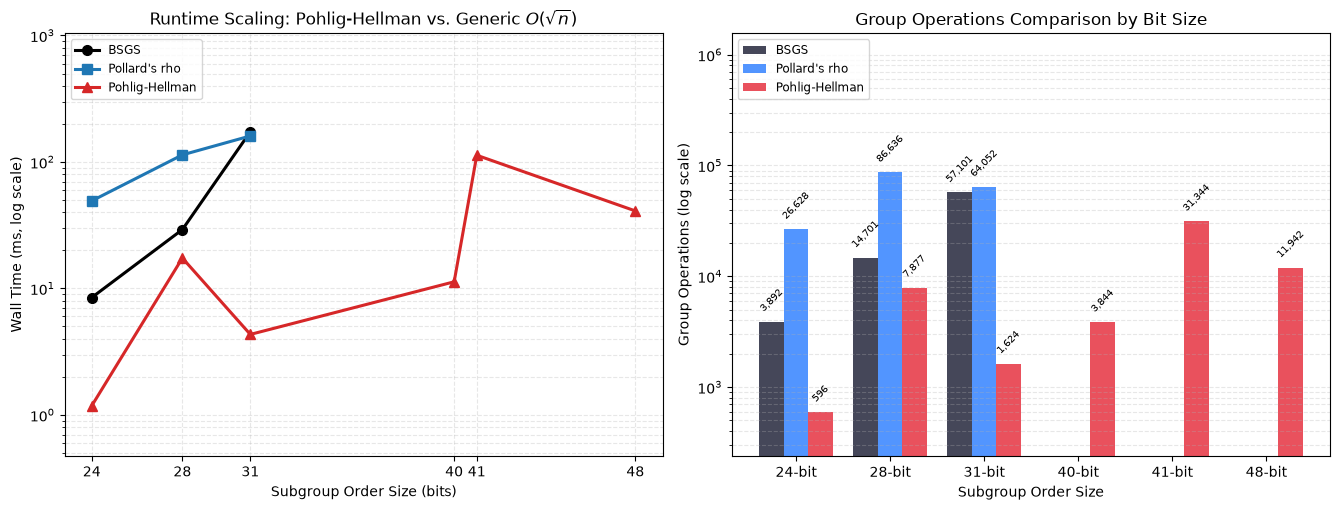

In [22]:
import statistics
import numpy as np
import matplotlib.pyplot as plt

STYLES = {
    "BSGS": ("k", "o"),
    "Pollard_Rho": ("tab:blue", "s"),
    "Pohlig_Hellman": ("tab:red", "^"),
}

BAR_COLORS = {
    "BSGS": "#2b2d42",
    "Pollard_Rho": "#3a86ff",
    "Pohlig_Hellman": "#e63946",
}


def plot_benchmarks(res_list: List[dict], out_path=None, show: bool = True) -> None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2))
    all_bits = sorted({r["n_bits"] for r in res_list})

    # 1. Left: Line graph — Wall-clock runtime across bit sizes (log scale)
    all_walls = []
    for name, (c, m) in STYLES.items():
        by_bits: Dict[int, List[float]] = {}
        for r in res_list:
            if name in r["algos"]:
                by_bits.setdefault(r["n_bits"], []).append(ms(r["algos"][name]))
        if by_bits:
            xs = sorted(by_bits)
            ys = [statistics.median(by_bits[x]) for x in xs]
            all_walls.extend(ys)
            ax1.plot(
                xs,
                ys,
                marker=m,
                color=c,
                linewidth=2.2,
                markersize=7,
                label=ALGO_LABELS.get(name, name),
            )

    ax1.set_yscale("log")
    if all_walls:
        ax1.set_ylim(min(all_walls) * 0.4, max(all_walls) * 6.0)
    ax1.set_xticks(all_bits)
    ax1.set_xlabel("Subgroup Order Size (bits)")
    ax1.set_ylabel("Wall Time (ms, log scale)")
    ax1.set_title("Runtime Scaling: Pohlig-Hellman vs. Generic $O(\\sqrt{n})$")
    ax1.grid(True, alpha=0.3, which="both", linestyle="--")
    ax1.legend(fontsize=8.5, loc="upper left")

    # 2. Right: Grouped bar chart — Median Group Operations per bit size (log scale)
    x_idx = np.arange(len(all_bits))
    algos_order = ["BSGS", "Pollard_Rho", "Pohlig_Hellman"]
    width = 0.26
    all_ops = []

    for i, name in enumerate(algos_order):
        medians = []
        for b in all_bits:
            vals = [r["algos"][name]["group_ops"] for r in res_list if r["n_bits"] == b and name in r["algos"]]
            med = statistics.median(vals) if vals else np.nan
            medians.append(med)
            if not np.isnan(med):
                all_ops.append(med)

        offset = (i - 1) * width
        bars = ax2.bar(
            x_idx + offset,
            medians,
            width=width,
            color=BAR_COLORS[name],
            alpha=0.88,
            label=ALGO_LABELS.get(name, name),
        )
        for bar, val in zip(bars, medians):
            if not np.isnan(val):
                ax2.text(
                    bar.get_x() + bar.get_width() / 2,
                    val * 1.18,
                    f"{int(val):,}",
                    ha="center",
                    va="bottom",
                    fontsize=7,
                    rotation=45,
                )

    ax2.set_yscale("log")
    if all_ops:
        ax2.set_ylim(max(1.0, min(all_ops) * 0.4), max(all_ops) * 18.0)
    ax2.set_xticks(x_idx)
    ax2.set_xticklabels([f"{b}-bit" for b in all_bits])
    ax2.set_xlabel("Subgroup Order Size")
    ax2.set_ylabel("Group Operations (log scale)")
    ax2.set_title("Group Operations Comparison by Bit Size")
    ax2.grid(True, axis="y", alpha=0.3, which="both", linestyle="--")
    ax2.legend(fontsize=8.5, loc="upper left")

    fig.tight_layout()
    if out_path is not None:
        Path(out_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_path, dpi=300, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


OUT_CHART = CHARTS_DIR / "pohlig_hellman_smooth.png"
plot_benchmarks(results_all, OUT_CHART)

## Bước 5 – Selftest và giao diện dòng lệnh

Theo đúng convention của các file trước: `selftest()` kiểm tra đúng đắn + nhất quán chi phí (nay có thêm rho và bộ đếm phép
toán), `main(argv)` chạy benchmark hàng loạt rồi ghi CSV, gọi được trực tiếp trong notebook qua `main([...])`.
`--out-d2` chỉ ghi vào `D2_ecdlp_benchmarks.csv` khi được yêu cầu rõ ràng, để lần chạy demo nhỏ không ghi đè bộ dữ liệu đầy đủ.

In [23]:
import argparse
import itertools

try:
    from curves.pohlig_hellman import crt_combine
except ImportError:
    from math import gcd

    def crt_combine(remainders: List[int], moduli: List[int]) -> Tuple[int, int]:
        x, m = 0, 1
        for r, mod in zip(remainders, moduli):
            g = gcd(m, mod)
            if (r - x) % g != 0:
                raise ValueError("Hệ đồng dư vô nghiệm")
            m1, m2 = m // g, mod // g
            inv = pow(m1, -1, m2)
            x += m * (((r - x) // g * inv) % m2)
            m *= m2
            x %= m
        return x, m


def write_d2_csv(res_list: List[dict], path) -> Tuple[int, int]:
    """Gộp kết quả smooth vào schema chung D2_ecdlp_benchmarks.csv."""
    cols = [
        "curve_type", "target_bits", "prime_p", "subgroup_order", "order_bits",
        "algorithm", "secret_k", "wall_time_ns", "cpu_time_ns", "cpu_cycles",
        "cycles_source", "ec_add_ops", "ec_double_ops", "ec_mul_ops",
        "total_ec_ops", "memory_peak_kib", "rss_peak_kib",
    ]
    path_ = Path(path)
    existing_rows = []
    if path_.exists():
        with open(path_, mode="r", encoding="utf-8") as f:
            for row in csv.DictReader(f):
                ctype = row.get("curve_type") or "standard"
                if ctype != "smooth":
                    row["curve_type"] = ctype
                    existing_rows.append(row)

    smooth_rows = []
    for r in res_list:
        for algo_name, a in r["algos"].items():
            smooth_rows.append({
                "curve_type": "smooth",
                "target_bits": r.get("target_bits", r["n_bits"]),
                "prime_p": r["p"],
                "subgroup_order": r["n"],
                "order_bits": r["n_bits"],
                "algorithm": algo_name,
                "secret_k": r["d_true"],
                "wall_time_ns": a["wall_time_ns"],
                "cpu_time_ns": a["cpu_time_ns"],
                "cpu_cycles": a["cpu_cycles"],
                "cycles_source": a["cycles_source"],
                "ec_add_ops": a["ec_add_ops"],
                "ec_double_ops": a["ec_double_ops"],
                "ec_mul_ops": a["ec_mul_ops"],
                "total_ec_ops": a["total_ec_ops"],
                "memory_peak_kib": a["memory_peak_kib"],
                "rss_peak_kib": a["rss_peak_kib"],
            })

    final_rows = existing_rows + smooth_rows
    final_rows.sort(key=lambda x: (x["curve_type"], int(x["target_bits"]), x["algorithm"]))
    path_.parent.mkdir(parents=True, exist_ok=True)
    with open(path_, mode="w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=cols, extrasaction="ignore")
        w.writeheader()
        w.writerows(final_rows)
    return len(existing_rows), len(smooth_rows)


def selftest() -> bool:
    ok = True
    E = ECC(2, 3, 97)
    P = Point(E, 3, 6)
    order = FindOrder(P)

    print("[1] BSGS_ECC giải đúng trên nhóm con nhỏ (F_97)")
    for d in (1, 5, order - 1):
        Q = (d % order) * P
        rec = BSGS_ECC(Q, P)
        good = rec == d % order
        ok &= good
        print(f"    d={d % order:<4} -> BSGS_ECC={rec} {'OK' if good else 'FAIL'}")

    print("[2] pohlig_hellman_ecc khớp BSGS_ECC trên cùng ví dụ")
    for d in (2, order // 2, order - 2):
        Q = (d % order) * P
        rec = pohlig_hellman_ecc(Q, P)
        good = rec == d % order
        ok &= good
        print(f"    d={d % order:<4} -> pohlig_hellman_ecc={rec} {'OK' if good else 'FAIL'}")

    print("[3] Trên curve smooth: PH đúng và group_ops <= BSGS toàn nhóm")
    for label, a, b, p in SMOOTH_CURVE_SPECS[:3]:
        row = spec_to_d1_row(label, a, b, p)
        res = benchmark_curve(row, seed=row["n_bits"], repeat=1)
        al = res["algos"]
        good = all(x["correct"] for x in al.values()) and al["Pohlig_Hellman"]["group_ops"] <= al["BSGS"]["group_ops"]
        ok &= good
        print(
            f"    n_bits={res['n_bits']:<3} bsgs_ops={al['BSGS']['group_ops']:<8} "
            f"rho_ops={al['Pollard_Rho']['group_ops']:<8} "
            f"ph_ops={al['Pohlig_Hellman']['group_ops']:<6} {'OK' if good else 'FAIL'}"
        )

    print("[4] crt_combine tự kiểm (CRT tay vs modulo trực tiếp)")
    good_all = True
    for r2, r3, r5 in itertools.product(range(2), range(3), range(5)):
        x, M = crt_combine([r2, r3, r5], [2, 3, 5])
        good_all &= (x % 2 == r2 and x % 3 == r3 and x % 5 == r5 and M == 30)
    ok &= good_all
    print(f"    {'OK' if good_all else 'FAIL'}")

    print("[5] Pollard_Rho_ECC khôi phục đúng mọi d trên F_97 và trên curve smooth 24-bit")
    good5 = all(Pollard_Rho_ECC(d * P, P) == d for d in range(1, order))
    row24 = spec_to_d1_row(*SMOOTH_CURVE_SPECS[0])
    E24 = curve_from_row(row24)
    pt24 = base_point_from_row(row24)
    G24 = pt24 if isinstance(pt24, Point) else Point(E24, pt24[0], pt24[1])
    n24 = int(row24["subgroup_n"])
    for d in (1, n24 // 3, n24 - 1):
        good5 &= (Pollard_Rho_ECC(d * G24, G24) == d)
    ok &= good5
    print(f"    {'OK' if good5 else 'FAIL'}")

    print("[6] track_ecc_ops đếm được phép toán và khôi phục Point.__add__/__mul__ sau khi thoát")
    add_before, mul_before = Point.__add__, Point.__mul__
    with track_ecc_ops() as ops:
        _ = 5 * P
    good6 = ops.total_ops > 0 and ops.mul_ops == 1 and Point.__add__ is add_before and Point.__mul__ is mul_before
    ok &= good6
    print(f"    add={ops.add_ops} double={ops.double_ops} mul={ops.mul_ops} {'OK' if good6 else 'FAIL'}")

    print("SELFTEST:", "PASS" if ok else "FAIL")
    return ok


def main(argv: Optional[List[str]] = None) -> int:
    ap = argparse.ArgumentParser(description="Thực thi Pohlig-Hellman trên smooth curve, so sánh chi phí.")
    ap.add_argument("--selftest", action="store_true")
    ap.add_argument("--min-bits", type=int, default=24)
    ap.add_argument("--max-bits", type=int, default=48)
    ap.add_argument("--seed", type=int, default=21)
    ap.add_argument("--no-rho", action="store_true", help="bỏ qua Pollard's rho")
    ap.add_argument("--max-generic-bits", type=int, default=32, help="chỉ chạy BSGS/rho khi n <= số bit này")
    ap.add_argument("--out", default=None, help="CSV theo curve (có chi phí ước lượng), vd data/D2_ecdlp_ph_smooth_benchmarks.csv")
    ap.add_argument("--append", action="store_true", help="nối thêm vào --out thay vì ghi đè")
    ap.add_argument("--out-d2", default=None, help="gộp vào D2 dùng chung, vd data/D2_ecdlp_benchmarks.csv")
    args = ap.parse_args(argv)

    if args.selftest:
        return 0 if selftest() else 1

    selected_specs = [
        spec for spec in SMOOTH_CURVE_SPECS
        if args.min_bits <= int(spec[0].split("-")[0]) <= args.max_bits
    ]
    rows = [spec_to_d1_row(*spec) for spec in selected_specs]
    res_list = [
        benchmark_curve(r, seed=args.seed + i, with_rho=not args.no_rho, max_generic_bits=args.max_generic_bits)
        for i, r in enumerate(rows)
    ]
    for res in res_list:
        al = res["algos"]
        extra = f" rho_ops={al['Pollard_Rho']['group_ops']:<8}" if "Pollard_Rho" in al else ""
        sp = f"speedup={res['measured_speedup']:.1f}x" if res["measured_speedup"] is not None else "speedup=n/a"
        print(
            f"{res['curve_id']} n_bits={res['n_bits']:<3} "
            f"bsgs_ops={al['BSGS']['group_ops'] if 'BSGS' in al else '-':<8}"
            f"{extra} ph_ops={al['Pohlig_Hellman']['group_ops']:<6} {sp} "
            f"[{'OK' if all(a['correct'] for a in al.values()) else 'FAIL'}]"
        )
    if args.out:
        write_benchmark_csv(res_list, args.out, append=args.append)
        print(f"Đã ghi {sum(len(r['algos']) for r in res_list)} dòng -> {args.out}")
    if args.out_d2:
        n_old, n_new = write_d2_csv(res_list, args.out_d2)
        print(f"Đã gộp {n_old} dòng cũ + {n_new} dòng smooth -> {args.out_d2}")
    return 0 if all_correct(res_list) else 1

In [24]:
# Chạy thử: selftest + demo CLI
selftest()

[1] BSGS_ECC giải đúng trên nhóm con nhỏ (F_97)
    d=1    -> BSGS_ECC=1 OK
    d=0    -> BSGS_ECC=0 OK
    d=4    -> BSGS_ECC=4 OK
[2] pohlig_hellman_ecc khớp BSGS_ECC trên cùng ví dụ
    d=2    -> pohlig_hellman_ecc=2 OK
    d=2    -> pohlig_hellman_ecc=2 OK
    d=3    -> pohlig_hellman_ecc=3 OK
[3] Trên curve smooth: PH đúng và group_ops <= BSGS toàn nhóm
    n_bits=24  bsgs_ops=5420     rho_ops=11811    ph_ops=588    OK
    n_bits=28  bsgs_ops=14809    rho_ops=86235    ph_ops=8179   OK
    n_bits=31  bsgs_ops=34634    rho_ops=182231   ph_ops=1646   OK
[4] crt_combine tự kiểm (CRT tay vs modulo trực tiếp)
    OK
[5] Pollard_Rho_ECC khôi phục đúng mọi d trên F_97 và trên curve smooth 24-bit
    OK
[6] track_ecc_ops đếm được phép toán và khôi phục Point.__add__/__mul__ sau khi thoát
    add=1 double=3 mul=1 OK
SELFTEST: PASS


True

## Tổng kết

**Đã hiện thực:**
- `bsgs_dlp`: baby-step giant-step tổng quát, dùng làm cả baseline lẫn subroutine cho PH.
- `pollard_rho_dlp`: Pollard's rho (Floyd, partition 3 phần, xử lý trường hợp order hợp số) làm baseline generic thứ hai,
  bộ nhớ $O(1)$ thay vì $O(\sqrt{n})$ như BSGS.
- `crt_combine`: Định lý số dư Trung Hoa (Garner), ghép các $d \bmod q_i^{e_i}$ thành $d \bmod n$.
- `pohlig_hellman`: thuật toán Pohlig–Hellman đầy đủ, khai thác đúng phân tích thừa số `n_factorization` của D1.
- `benchmark_curve`: đo **thực tế** trên nhiều curve smooth 16–48 bit, cho từng thuật toán: `group_ops`, số phép cộng/nhân đôi/
  nhân vô hướng (`track_ecc_ops`), thời gian wall/CPU, cycles và đỉnh RAM; so với ước lượng lý thuyết
  `estimate_bsgs_cost`/`estimate_ph_cost`.
- `write_benchmark_csv` / `write_d2_csv`: ghi file theo curve (kèm chi phí ước lượng) và gộp vào `data/D2_ecdlp_benchmarks.csv`
  (giữ nguyên các dòng baseline `standard`, thay các dòng `smooth` cũ nên chạy lại không bị nhân đôi).
- `plot_benchmarks`: biểu đồ 2 panel (đo vs lý thuyết; thời gian wall) lưu tại `docs/charts/pohlig_hellman_smooth.png`.

**Kết quả quan sát:** số phép nhóm đo được của Pohlig–Hellman bám khá sát đường ước lượng lý
thuyết $\sum_i e_i\sqrt{q_i}$, trong khi BSGS toàn nhóm và Pollard's rho bám theo $\sqrt n$ — xác nhận thực nghiệm cho lý thuyết đã
trình bày ở notebook trước, và cho thấy mức "vỡ" tăng dần theo số bit khi order vẫn giữ nguyên ngưỡng $B$-smooth. Ở 40–48 bit,
nơi BSGS/rho cần ~$10^6$–$10^7$ phép nhóm, PH vẫn giải trong thời gian ngắn.

**Giới hạn đã biết:**
- `group_ops` chỉ đếm bước baby/giant (BSGS) và bước của dãy (rho) và các phép nhóm trong subroutine của PH, không tính chi phí
  $O(\log n)$ của phép chiếu nhóm con — khớp với đơn vị mà công thức lý thuyết dùng, nhưng là một xấp xỉ. Số liệu
  `track_ecc_ops` (đếm mọi phép cộng/nhân đôi kể cả bên trong nhân vô hướng) bổ sung cho giới hạn này.
- Thời gian/RAM phụ thuộc máy chạy; `cpu_cycles` có thể là ước lượng từ `cpu_time_ns` (cột `cycles_source` ghi rõ nguồn).
- Toy curve ≤ 48 bit; `bsgs_dlp` dùng dict Python nên tốn bộ nhớ $O(\sqrt{\text{order}})$ —
  không mở rộng được lên kích thước mật mã thật (đúng mục đích học thuật của Track A).

---

## Tài liệu tham khảo

Kế thừa danh sách tham khảo của `gen_smooth_curves.ipynb` (Pohlig & Hellman 1978; Wikipedia *Pohlig–Hellman
algorithm*; Galbraith/Auckland ch.13; Pintore, Oxford; NIST SP 800-186; FIPS 186-5; RFC 6090). Riêng phần cài đặt
CRT ở đây theo thuật toán Garner chuẩn (xem thêm: D. Knuth, *The Art of Computer Programming* Vol. 2, mục 4.3.2 —
*The Chinese Remainder Theorem*, một tài liệu kinh điển thường được trích trong các giáo trình số học tính toán). Pollard's rho
theo J. M. Pollard, *Monte Carlo methods for index computation (mod p)*, Math. Comp. 32 (1978).